In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Agent Repeatability and Clustering Reproducibility Analysis — PBMC3k

## Purpose

This notebook investigates the repeatability of an LLM-based clustering optimization agent on the PBMC3k single-cell RNA-seq dataset. The analysis examines whether repeated agent runs follow similar parameter-search trajectories, select comparable clustering configurations, and produce similar final cell partitions.

Three experiment batches are compared:

1. **Fixed Leiden seed — Batch A:** Eight agent runs with the LLM seed fixed at 42 and the Leiden seed fixed at 42.
2. **Fixed Leiden seed — Batch B:** A second set of eight agent runs using the same configured LLM and Leiden seeds, conducted as an independent repeatability batch.
3. **Varied Leiden seeds:** Eight agent runs with the LLM seed fixed at 42 and Leiden seeds varied across runs.

In all batches, the agent was allowed to explore the configured clustering parameter space, including `n_neighbors`, `n_pcs`, and `resolution`. The analysis therefore distinguishes repeatability of the agent's search and parameter selection from reproducibility of the final clustering results.

The varied-Leiden-seed batch is used to examine final-partition agreement when the Leiden random seed differs across runs. Comparisons between this batch and the fixed-seed batches are interpreted descriptively, since the selected parameters and resulting partitions may also differ.

## Experimental configuration

| Setting | Configuration |
|---|---|
| Dataset | PBMC3k |
| LLM | GPT-5 |
| Configured LLM seed | 42 |
| LLM temperature | 0 |
| Leiden seed — Batch A | Fixed at 42 |
| Leiden seed — Batch B | Fixed at 42 |
| Leiden seed — varied batch | Varied across eight runs |
| Optimization parameters | `n_neighbors`, `n_pcs`, `resolution` |
| Parameter selection | Agent-guided search within configured bounds |
| Runs per batch | Eight |
| Number of batches | Three |
| Clustering agreement metrics | ARI and NMI |

## Interpretation and scope

ARI and NMI quantify agreement between partitions; they do not independently establish biological validity or clustering quality. Parameter repeatability, partition reproducibility, internal clustering metrics, and biological interpretability are treated as related but distinct aspects of the evaluation.


## Load the three experiment paths

In [3]:
project_dir = Path.cwd()

experiment_dirs = {
    "Fixed Leiden seed — Batch A": (
        project_dir / "experiments"
        / "llm_seed42_agent_repeatability_20261018_222712_094535"
        / "new_analysis_k9"
    ),
    "Fixed Leiden seed — Batch B": (
        project_dir / "experiments"
        / "llm_seed42_agent_repeatability_20261018_231507_970469"
        / "new_analysis_k9"
    ),
    "Varied Leiden seeds": (
        project_dir / "experiments"
        / "llm_seed42_agent_varied_leiden_20261019_104037_105953"
        / "new_analysis_k9"
    ),
}


### Load all final-selection tables
This creates one combined table while preserving which batch each run came from.

In [21]:
selection_tables = {}
trajectory_tables = {}
ari_matrices = {}
nmi_matrices = {}
pairwise_tables = {}
readme_data = {}

for batch, path in experiment_dirs.items():

    selection_tables[batch] = pd.read_csv(
        path / "new_final_best_selection_table.csv"
    ).assign(experiment_batch=batch)

    trajectory_tables[batch] = pd.read_csv(
        path / "new_iteration_trajectory_table.csv"
    ).assign(experiment_batch=batch)

    ari_matrices[batch] = pd.read_csv(
        path / "new_final_best_ari_matrix.csv",
        index_col=0
    )

    nmi_matrices[batch] = pd.read_csv(
        path / "new_final_best_nmi_matrix.csv",
        index_col=0
    )

    pairwise_tables[batch] = pd.read_csv(
        path / "new_final_best_pairwise_similarity.csv"
    )

    with open(path / "new_analysis_readme.json", encoding="utf-8") as f:
        readme_data[batch] = json.load(f)

all_selections = pd.concat(
    selection_tables.values(),
    ignore_index=True,
    sort=False
)

all_trajectories = pd.concat(
    trajectory_tables.values(),
    ignore_index=True,
    sort=False
)

print("Combined final-selection table:", all_selections.shape)
print("Combined iteration-trajectory table:", all_trajectories.shape)

# display(all_selections)

Combined final-selection table: (24, 14)
Combined iteration-trajectory table: (313, 14)


In [6]:
preferred_columns = [
    "experiment_batch",
    "experiment_id",
    "run_index",
    "leiden_seed",
    "llm_seed",
    "selected_iteration",
    "selected_n_neighbors",
    "selected_n_pcs",
    "selected_resolution",
    "selected_n_clusters",
    "selected_largest_cluster_size",
]

available_columns = [
    col for col in preferred_columns
    if col in all_selections.columns
]

display(
    all_selections[available_columns]
    .sort_values(
        ["experiment_batch", "run_index"],
        na_position="last"
    )
    .reset_index(drop=True)
)

,experiment_batch,experiment_id,run_index,leiden_seed,llm_seed,selected_iteration,selected_n_neighbors,selected_n_pcs,selected_resolution
0,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,1,42,42,6,20,25,0.60
1,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,2,42,42,15,25,12,1.10
2,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,3,42,42,7,30,10,0.80
3,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,4,42,42,12,20,40,0.50
4,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,5,42,42,8,15,12,0.80
5,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,6,42,42,12,45,10,0.90
6,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,7,42,42,7,30,30,0.70
7,Fixed Leiden seed — Batch A,llm_seed42_agent_repeatability_20261018_222712...,8,42,42,7,15,20,0.60
8,Fixed Leiden seed — Batch B,llm_seed42_agent_repeatability_20261018_231507...,1,42,42,15,30,20,0.72
9,Fixed Leiden seed — Batch B,llm_seed42_agent_repeatability_20261018_231507...,2,42,42,7,20,10,0.80


### Display the saved parameter and metric trajectories


## Fixed Leiden seed — Batch A
Parameter trajectories


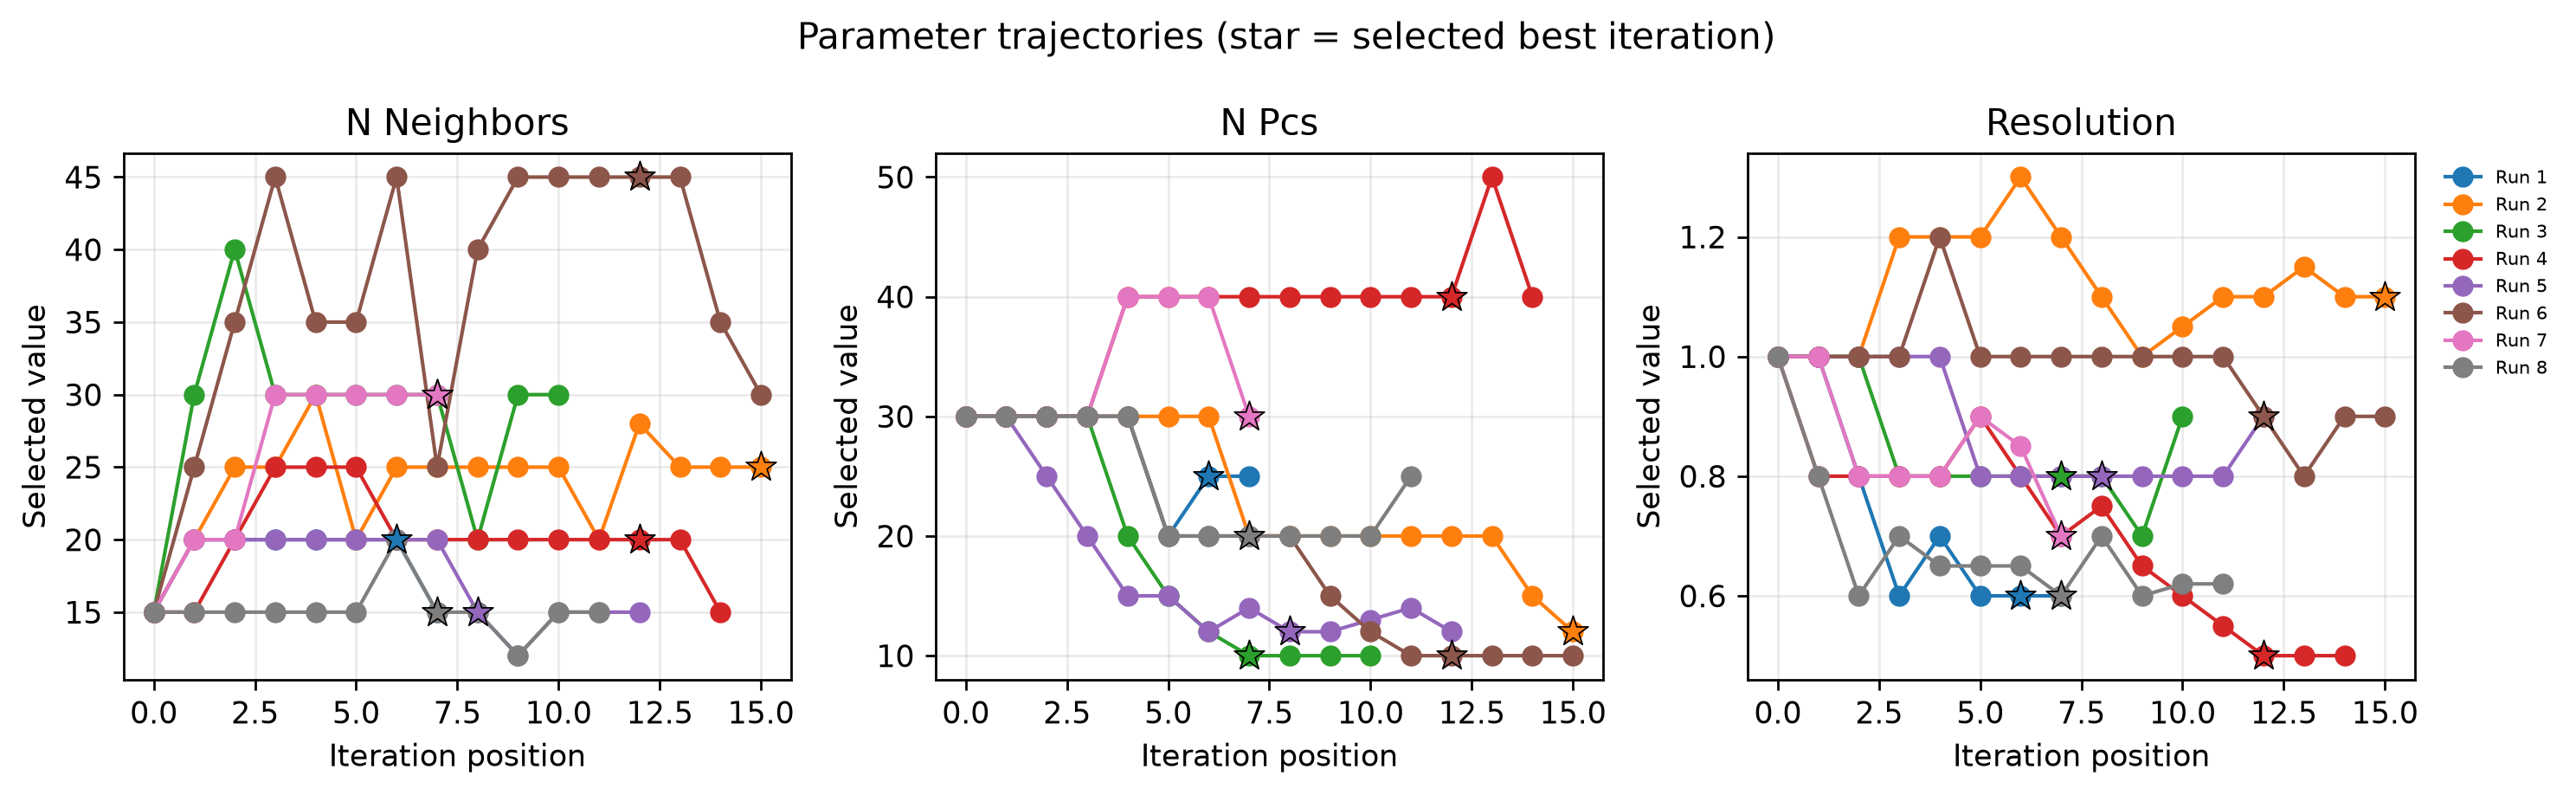

Metric trajectories


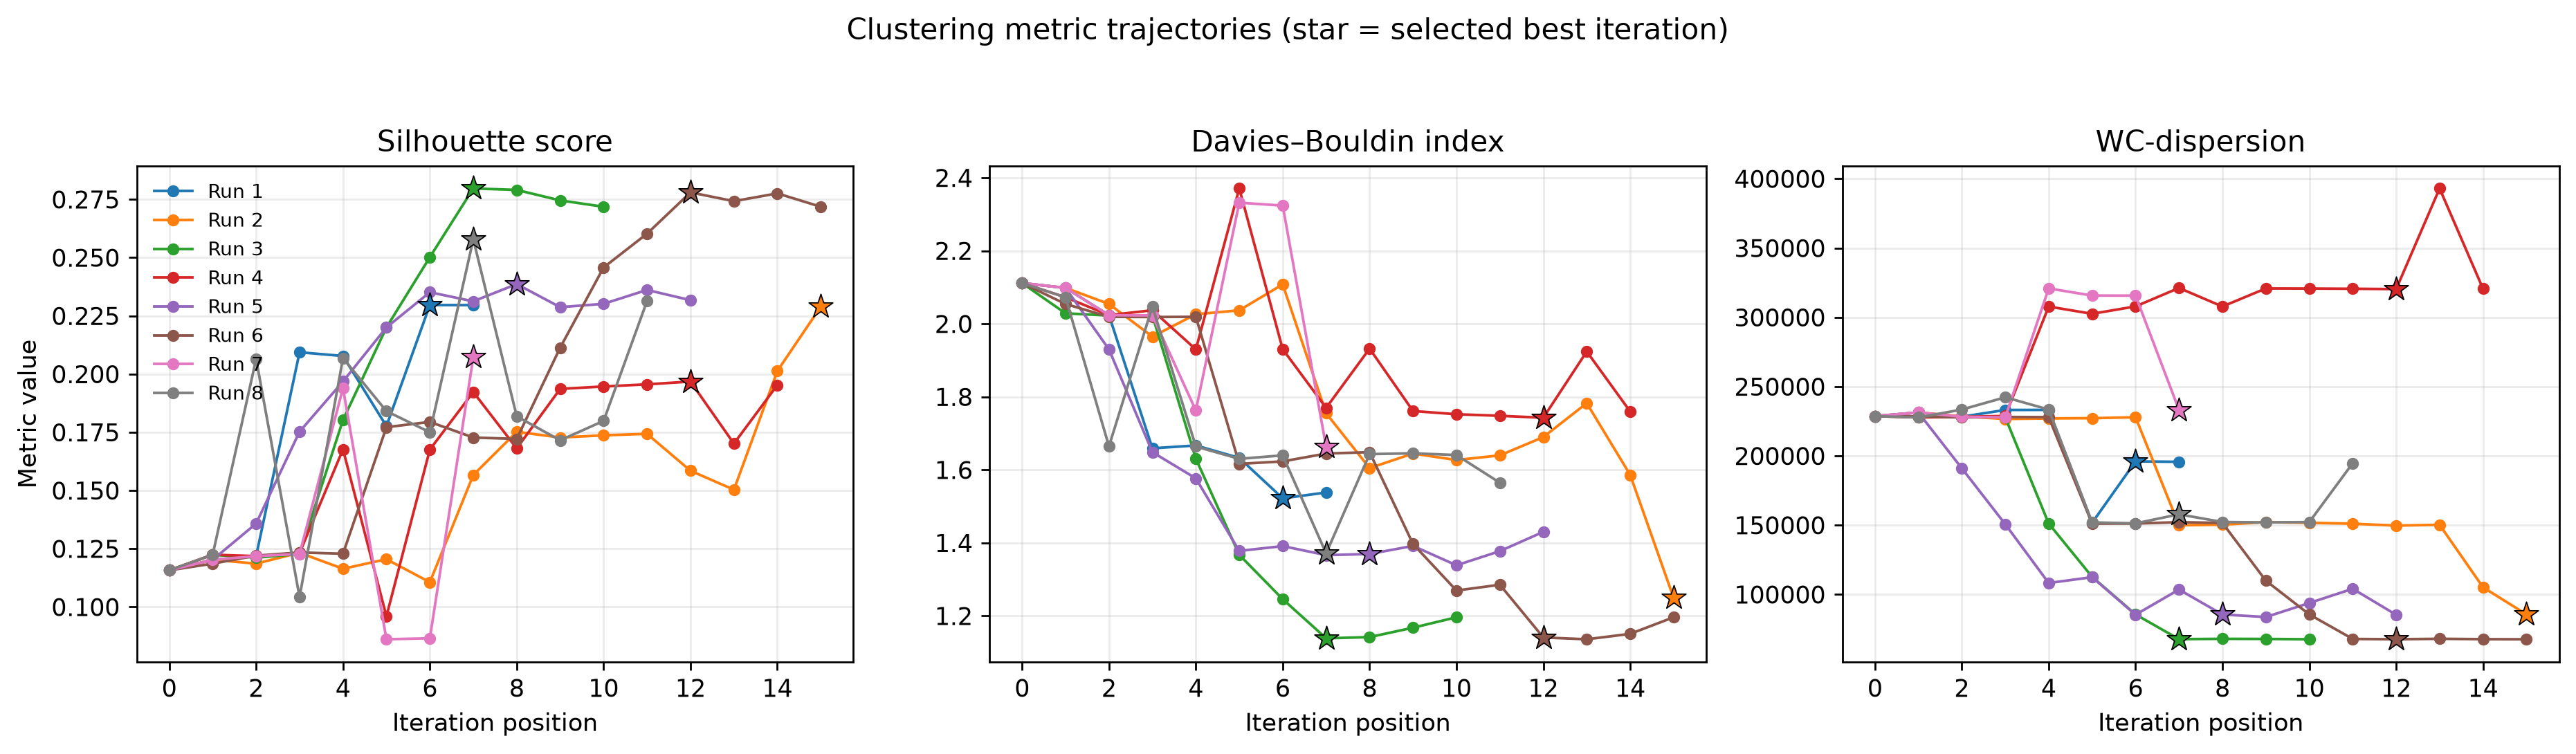


## Fixed Leiden seed — Batch B
Parameter trajectories


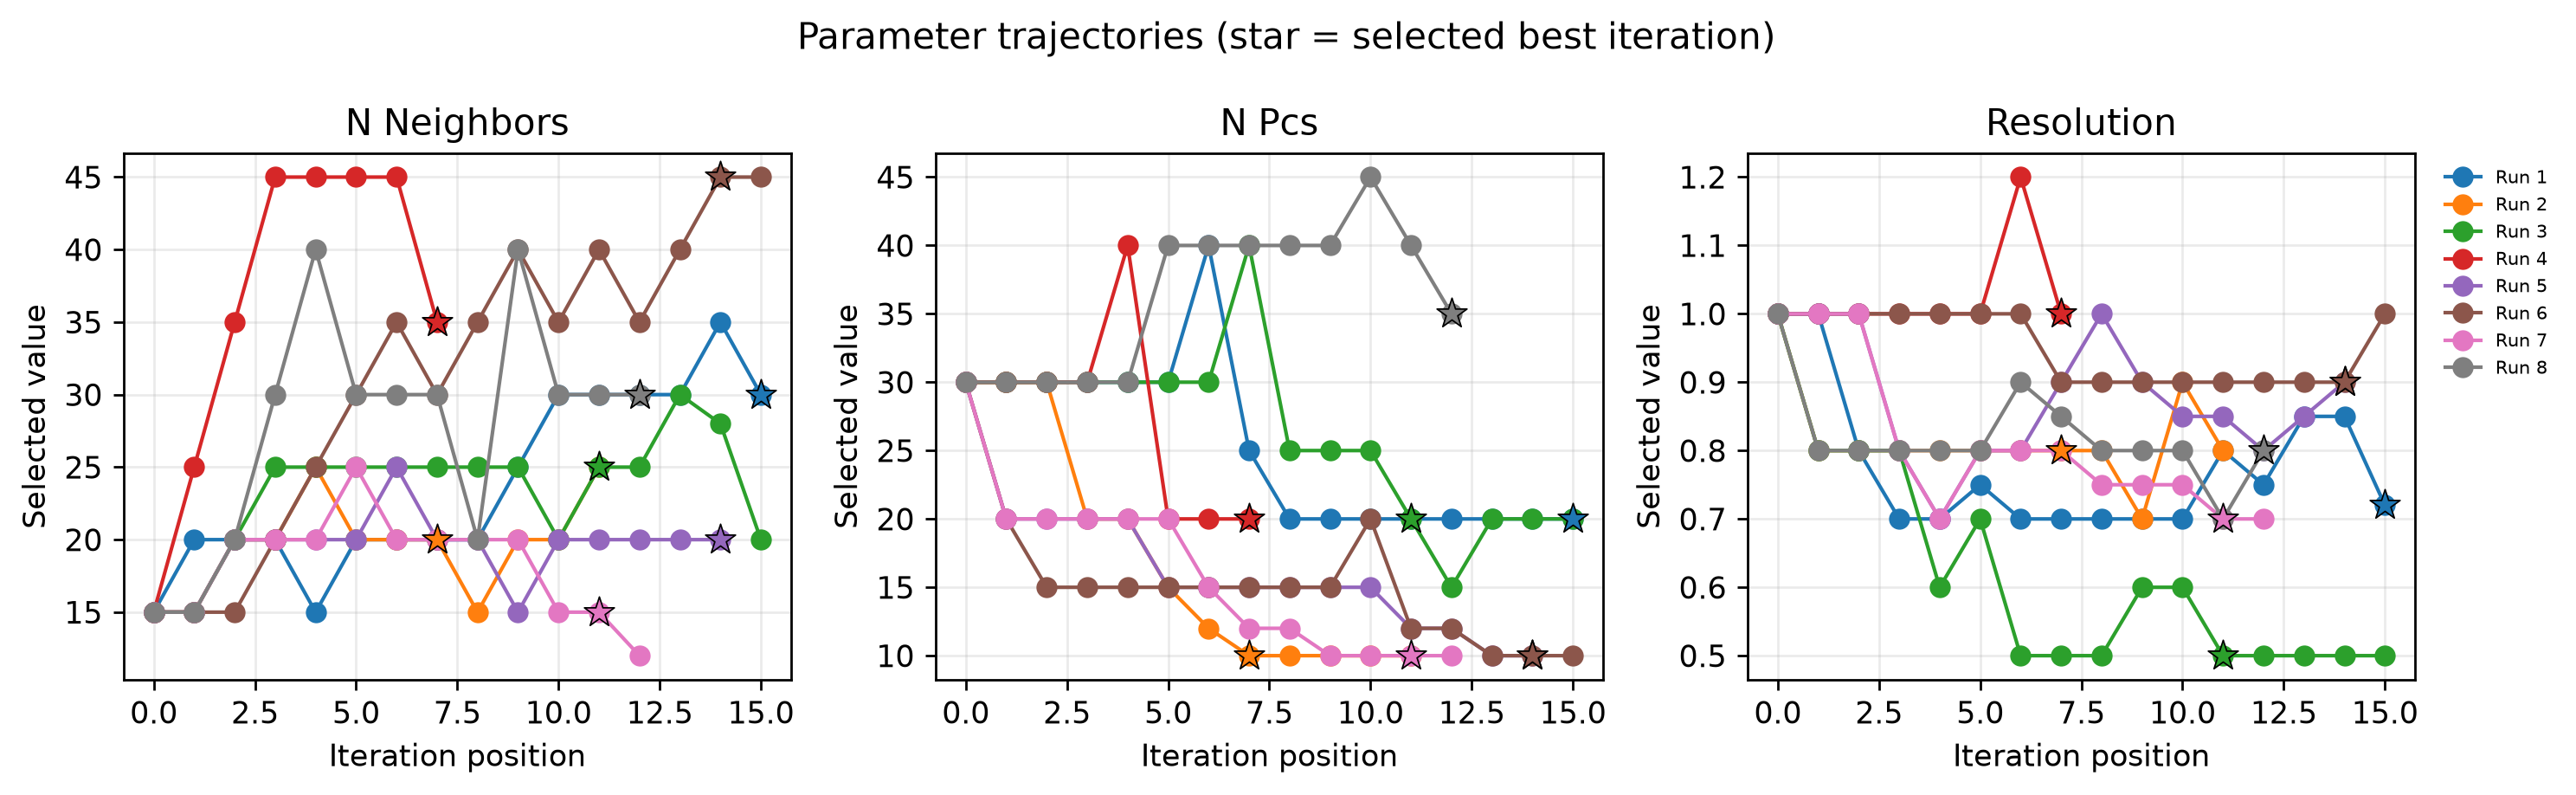

Metric trajectories


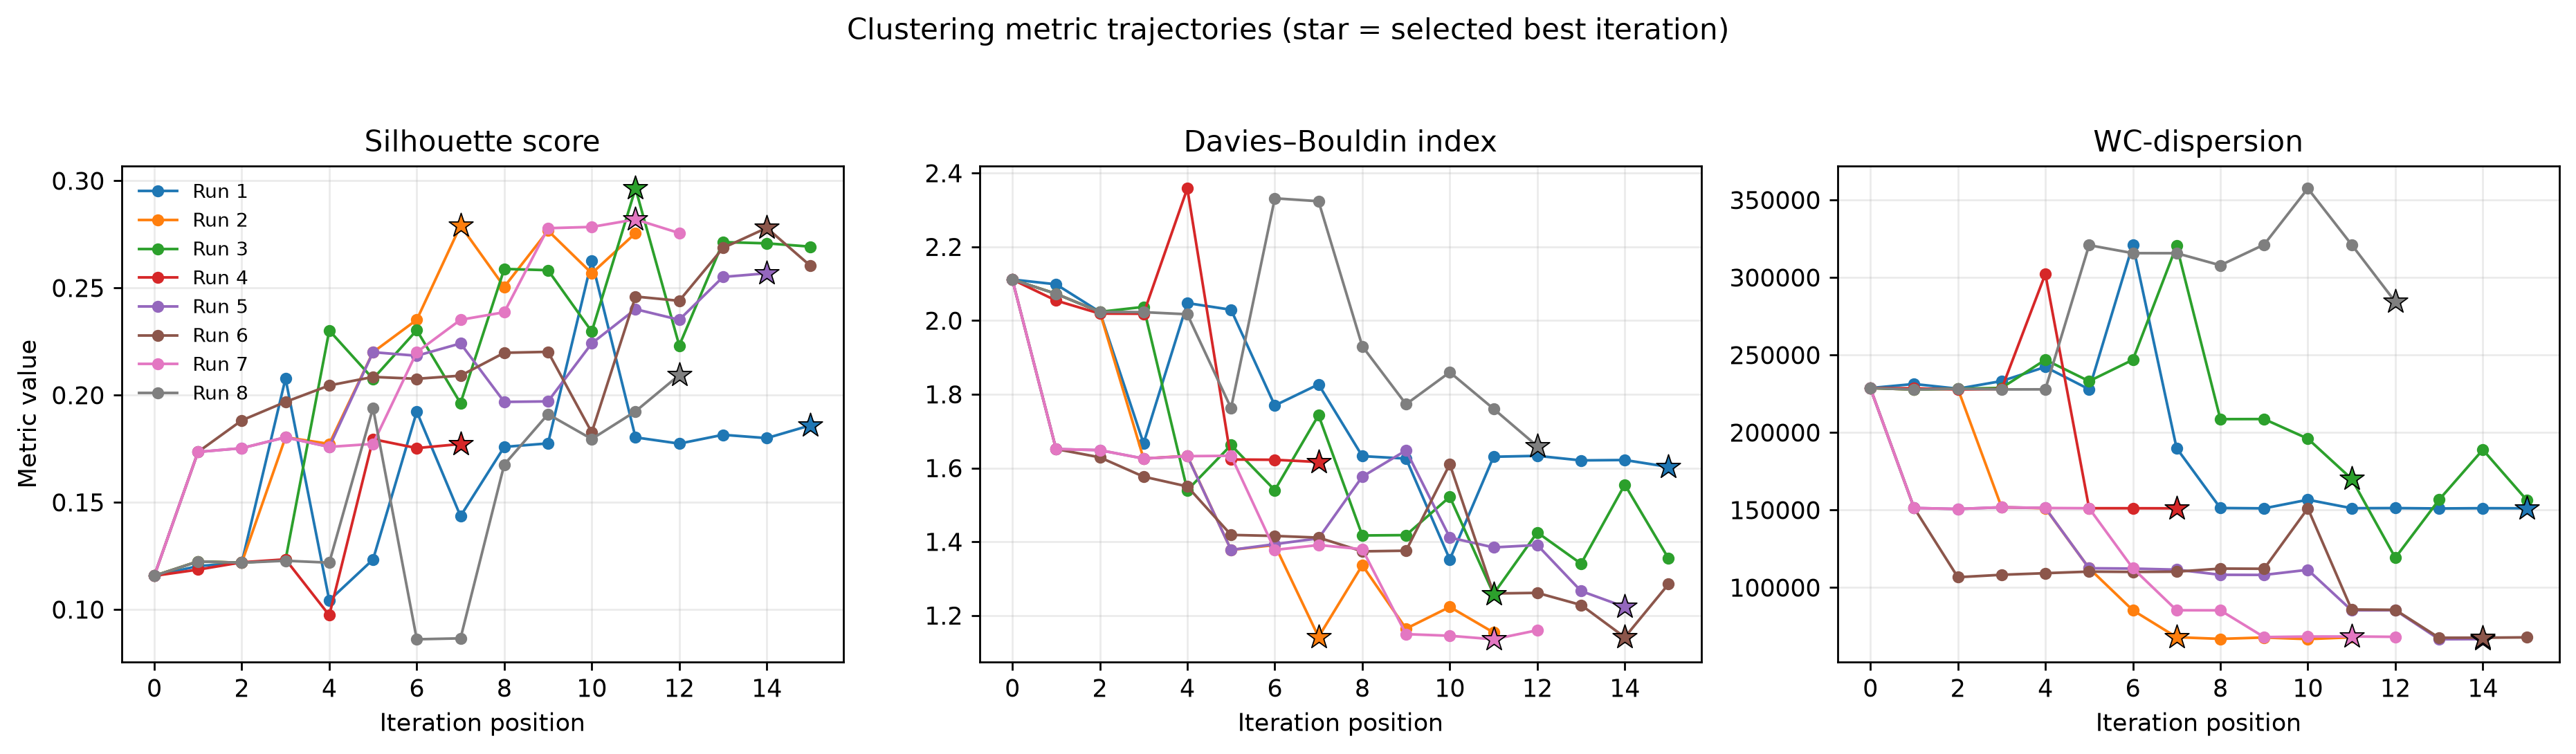


## Varied Leiden seeds
Parameter trajectories


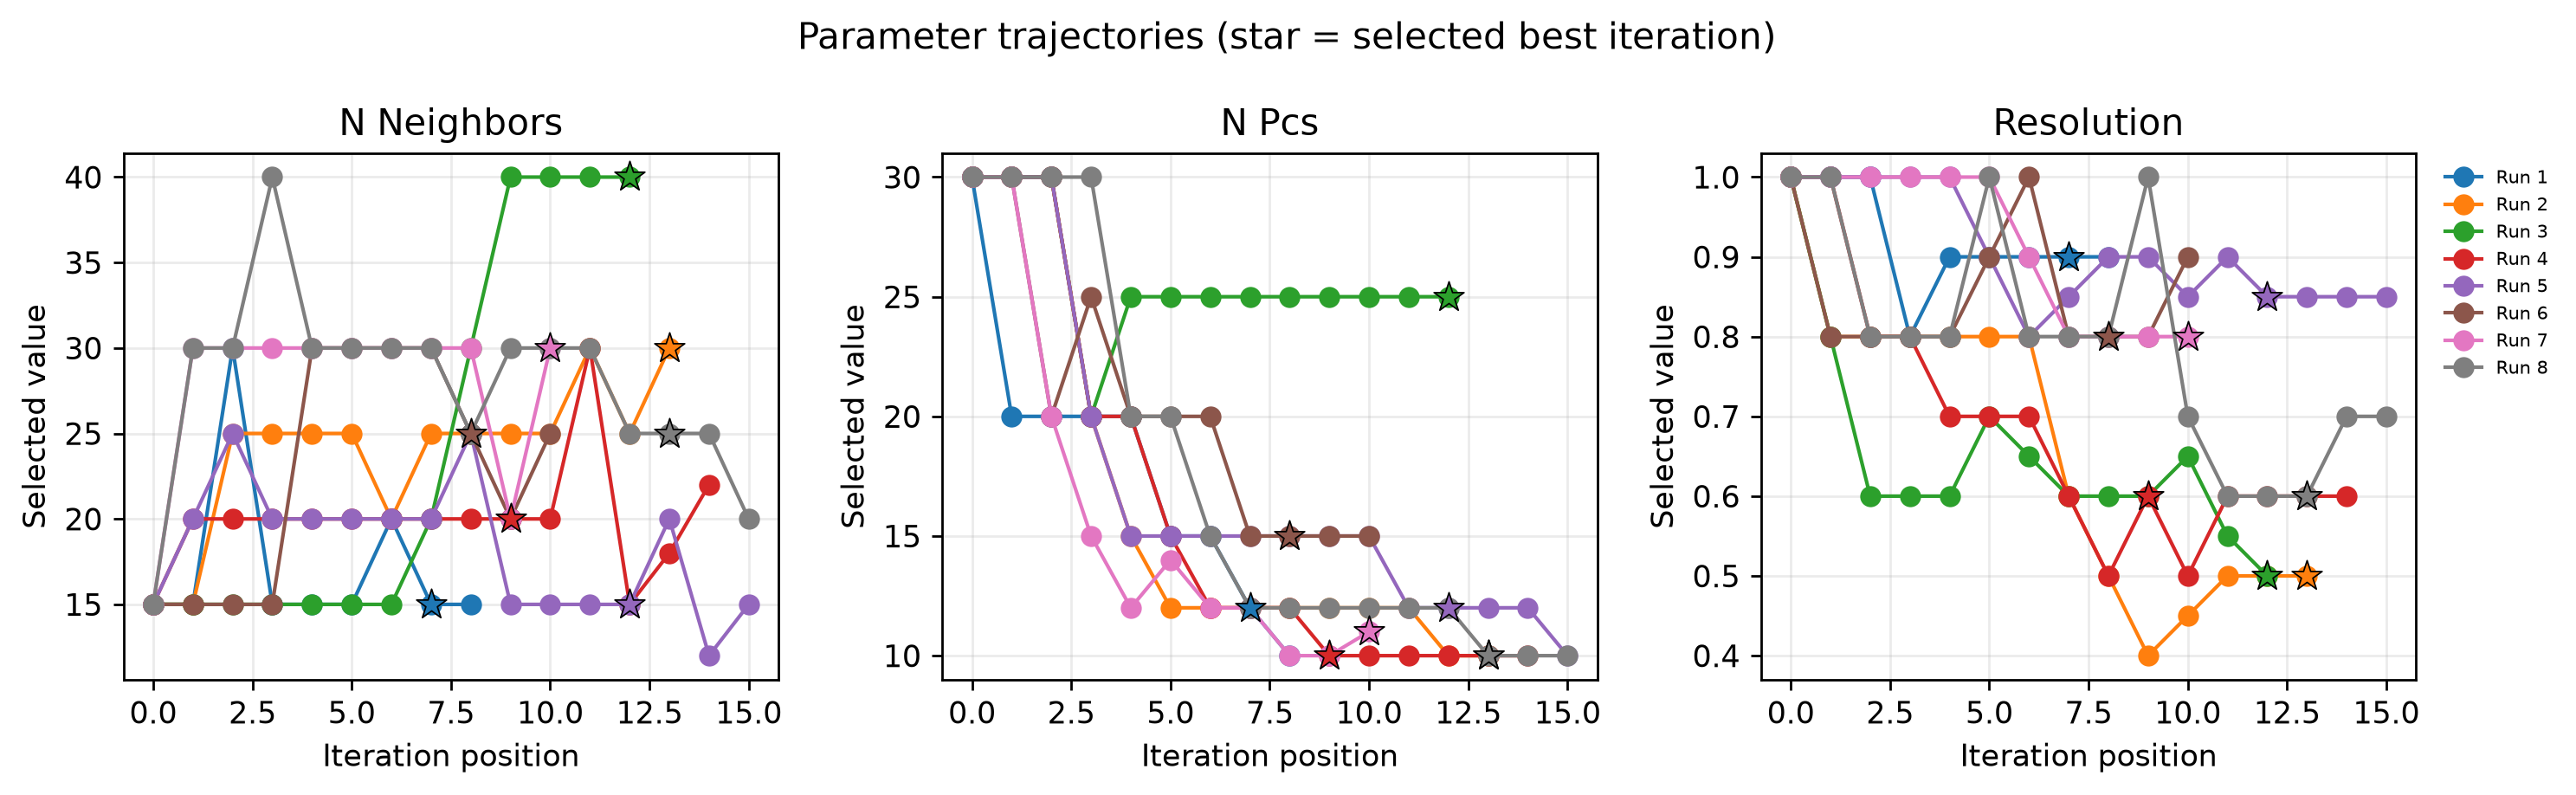

Metric trajectories


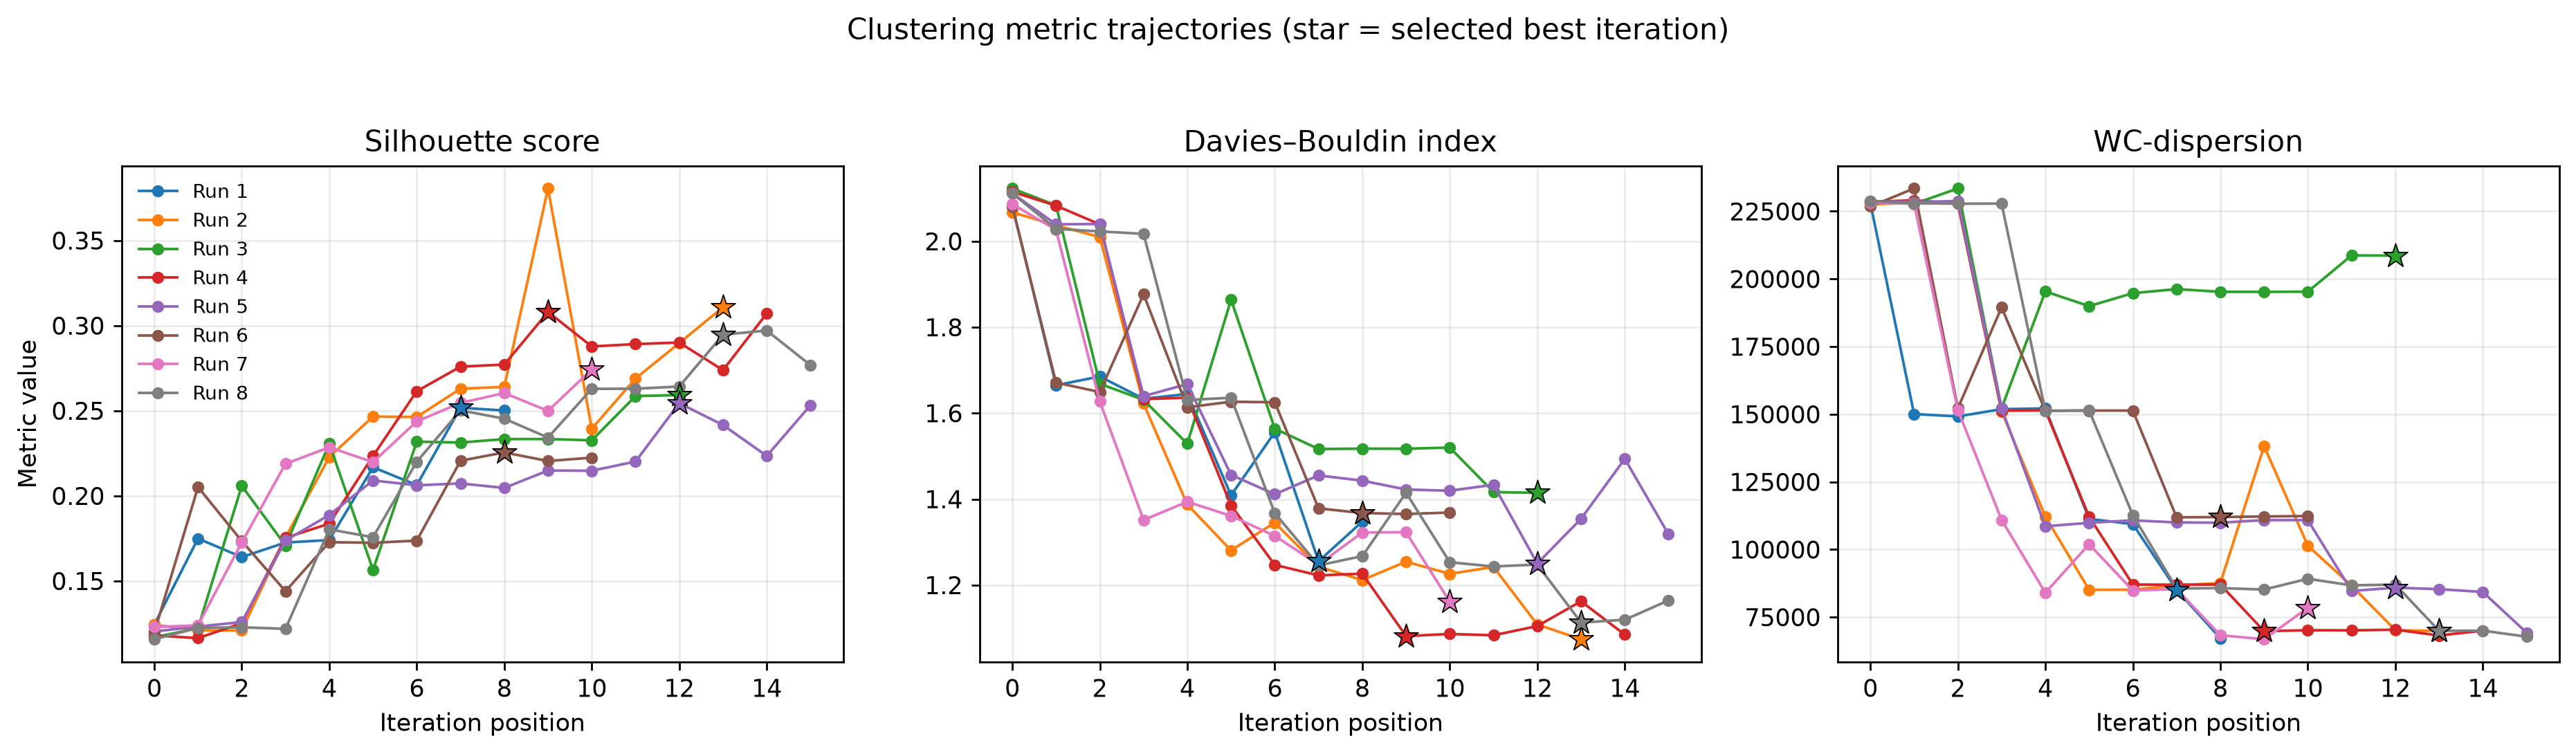

In [9]:
for batch, path in experiment_dirs.items():
    if not path.exists():
        continue

    print(f"\n## {batch}")

    for filename, title in [
        ("new_fig_parameter_trajectories.png",
         "Parameter trajectories"),
        ("new_fig_metric_trajectories.png",
         "Metric trajectories"),
    ]:
        figure_path = path / filename
        
        print(title)
        display(Image(filename=str(figure_path)))
        

### Compare the final selected parameters across batches
First, summarize how frequently each final parameter combination was selected.

In [10]:
parameter_columns = [
    "selected_n_neighbors",
    "selected_n_pcs",
    "selected_resolution",
]

if all(col in all_selections.columns for col in parameter_columns):
    selection_frequency = (
        all_selections
        .groupby(["experiment_batch"] + parameter_columns, dropna=False)
        .size()
        .reset_index(name="selection_count")
        .sort_values(
            ["experiment_batch", "selection_count"],
            ascending=[True, False]
        )
    )

    display(selection_frequency)

,experiment_batch,selected_n_neighbors,selected_n_pcs,selected_resolution,selection_count
0,Fixed Leiden seed — Batch A,15,12,0.80,1
1,Fixed Leiden seed — Batch A,15,20,0.60,1
2,Fixed Leiden seed — Batch A,20,25,0.60,1
3,Fixed Leiden seed — Batch A,20,40,0.50,1
4,Fixed Leiden seed — Batch A,25,12,1.10,1
5,Fixed Leiden seed — Batch A,30,10,0.80,1
6,Fixed Leiden seed — Batch A,30,30,0.70,1
7,Fixed Leiden seed — Batch A,45,10,0.90,1
8,Fixed Leiden seed — Batch B,15,10,0.70,1
9,Fixed Leiden seed — Batch B,20,10,0.80,1


### Display pairwise ARI and NMI matrices
The saved matrices compare the final selected partitions within each experiment batch.

In [15]:
def plot_similarity_matrix(
    matrix,
    title,
    output_path=None,
    vmin=0,
    vmax=1
):
    matrix = matrix.apply(pd.to_numeric, errors="coerce")

    n = len(matrix)

    # Short, readable labels
    labels = [f"Run {i+1}" for i in range(n)]

    fig, ax = plt.subplots(figsize=(10, 8))

    im = ax.imshow(
        matrix.to_numpy(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=14, pad=14)
    ax.set_xlabel("Run", fontsize=12)
    ax.set_ylabel("Run", fontsize=12)

    ax.set_xticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=10)

    ax.set_yticks(range(n))
    ax.set_yticklabels(labels, fontsize=10)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Similarity", fontsize=11)

    # Add values to the cells
    for i in range(n):
        for j in range(n):
            value = matrix.iloc[i, j]
            if pd.notna(value):
                ax.text(
                    j, i, f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="black" if value > 0.65 else "white"
                )

    fig.tight_layout()

    if output_path is not None:
        fig.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

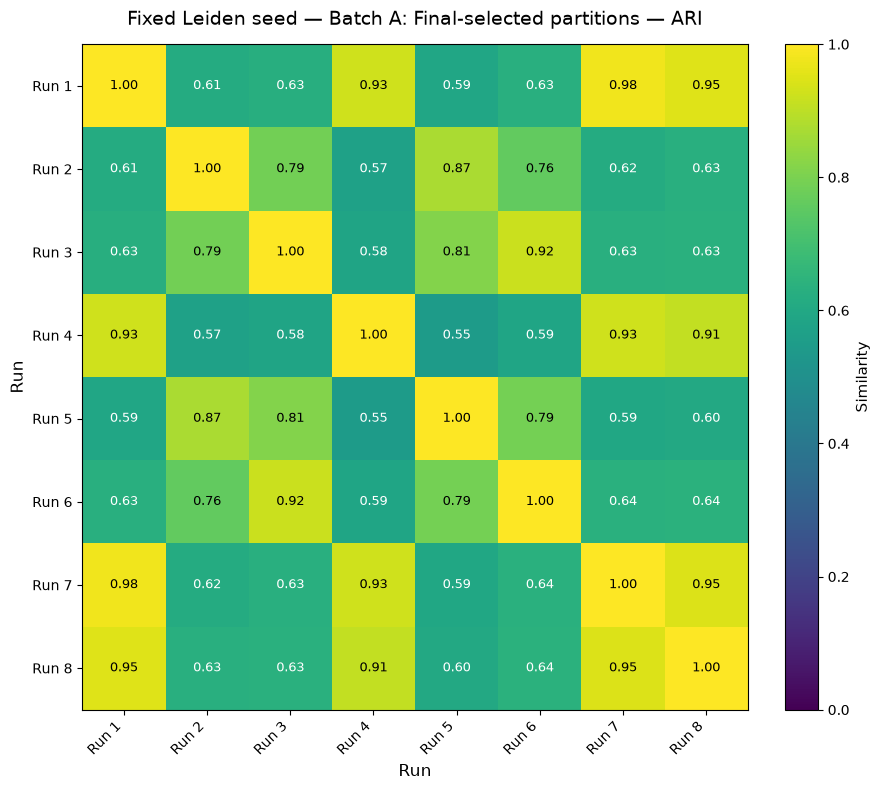

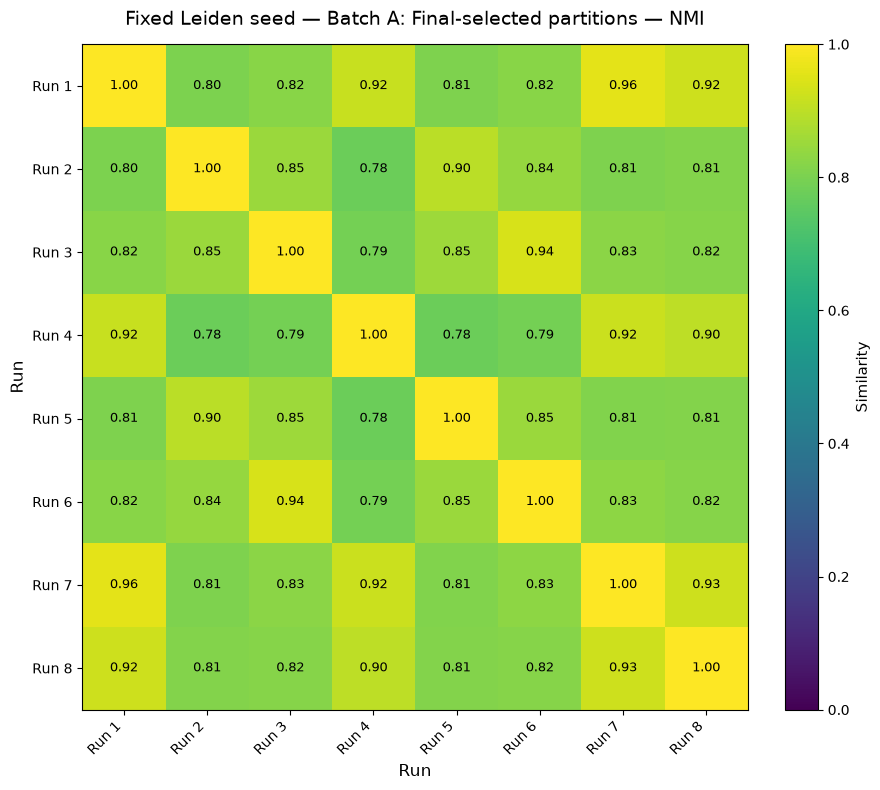

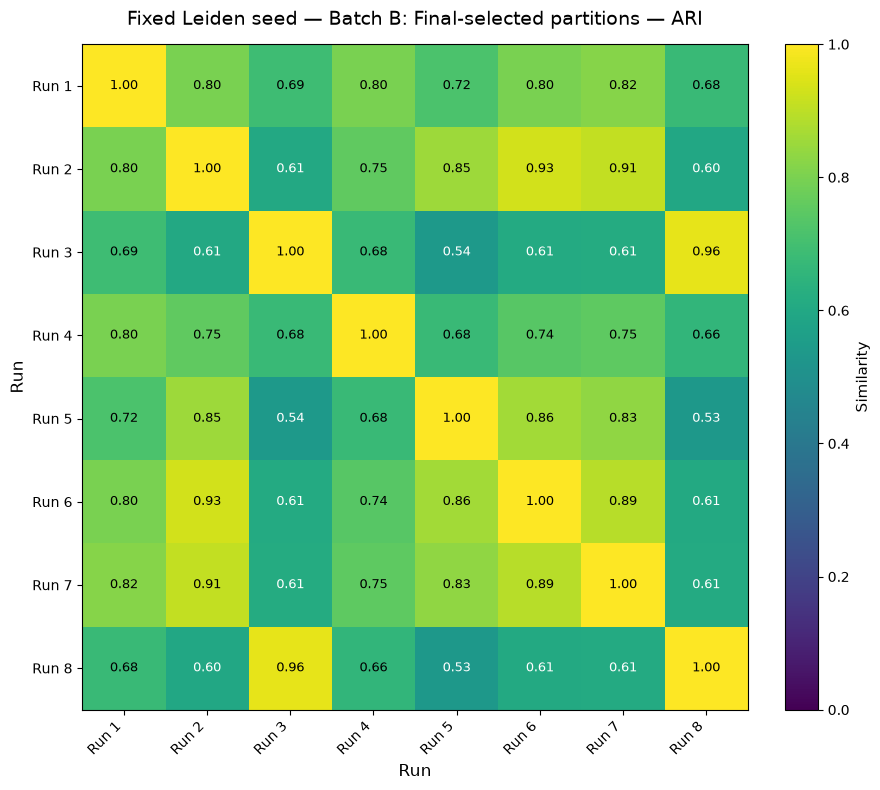

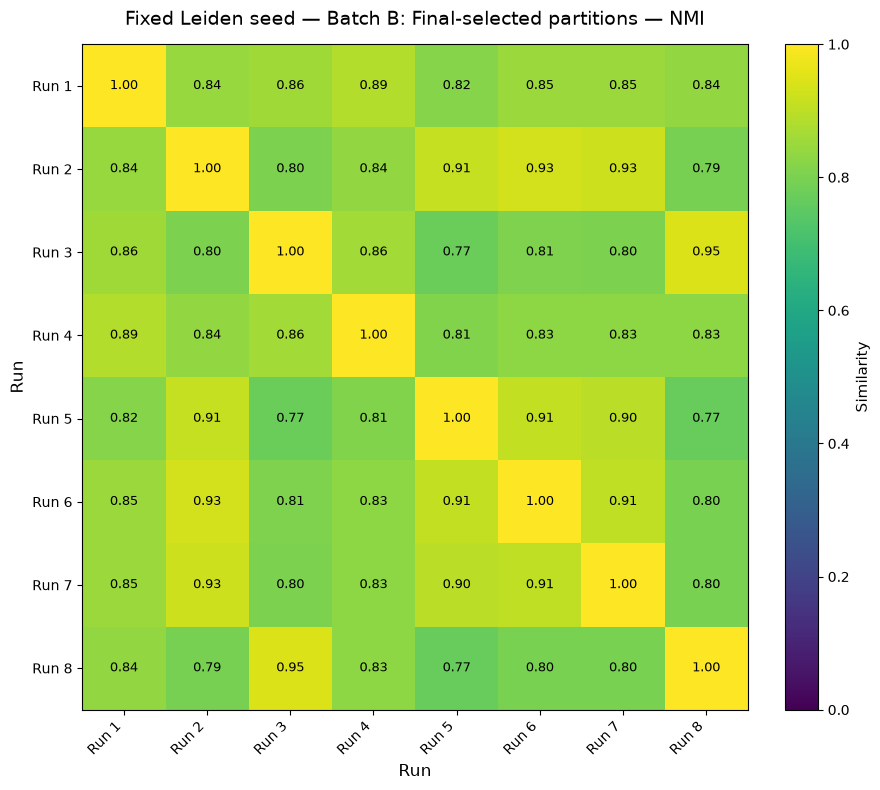

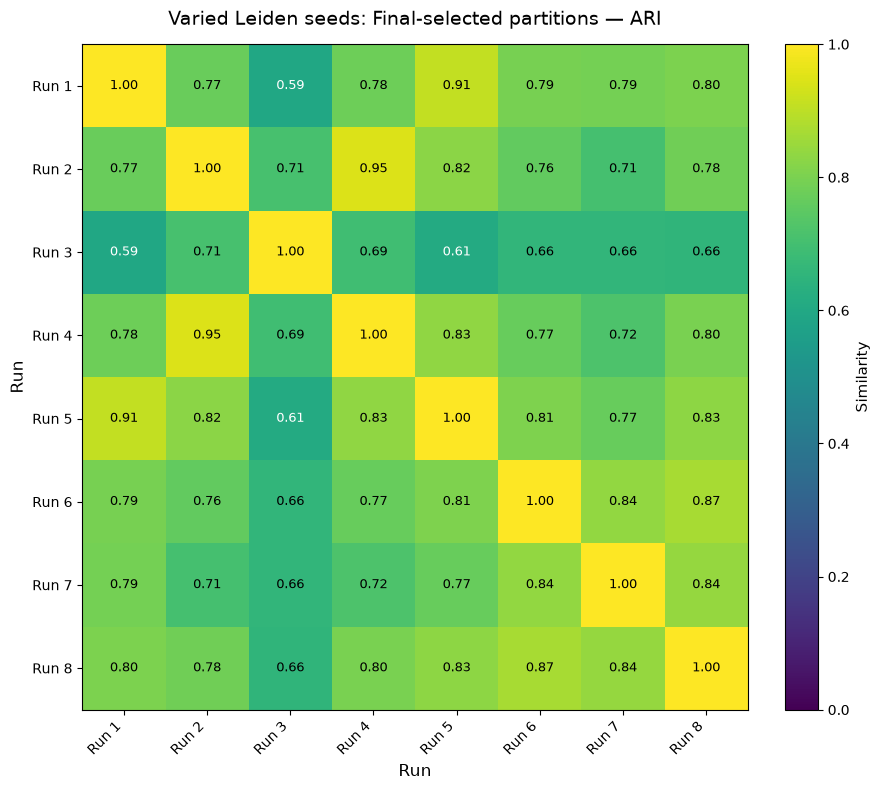

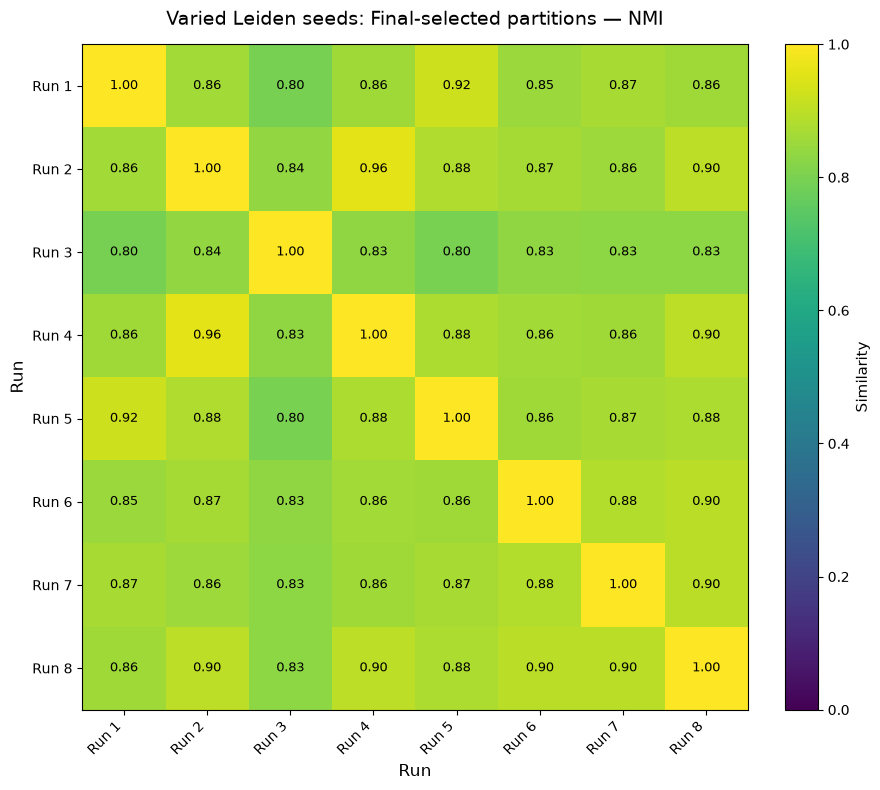

In [16]:
for batch in experiment_dirs:
    if batch in ari_matrices:
        plot_similarity_matrix(
            ari_matrices[batch],
            f"{batch}: Final-selected partitions — ARI",
            output_path=experiment_dirs[batch] / "clear_ari_heatmap.png"
        )

    if batch in nmi_matrices:
        plot_similarity_matrix(
            nmi_matrices[batch],
            f"{batch}: Final-selected partitions — NMI",
            output_path=experiment_dirs[batch] / "clear_nmi_heatmap.png"
        )

In [20]:
def summarize_similarity(matrix, batch, metric):
    values = matrix.apply(pd.to_numeric, errors="coerce").to_numpy()

    # Upper triangle only: excludes diagonal and duplicate pairs
    upper = values[np.triu_indices_from(values, k=1)]
    upper = upper[~np.isnan(upper)]

    return {
        "batch": batch,
        "metric": metric,
        "n_unique_pairs": len(upper),
        "mean": np.mean(upper),
        "median": np.median(upper),
        "min": np.min(upper),
        "max": np.max(upper),
    }

similarity_summary = pd.DataFrame([
    summarize_similarity(ari_matrices[batch], batch, "ARI")
    for batch in experiment_dirs
] + [
    summarize_similarity(nmi_matrices[batch], batch, "NMI")
    for batch in experiment_dirs
])

display(
    similarity_summary.round(3)
    .sort_values(["metric", "batch"])
    .reset_index(drop=True)
)

,batch,metric,n_unique_pairs,mean,median,min,max
0,Fixed Leiden seed — Batch A,ARI,28,0.726,0.635,0.547,0.978
1,Fixed Leiden seed — Batch B,ARI,28,0.733,0.727,0.535,0.961
2,Varied Leiden seeds,ARI,28,0.769,0.782,0.595,0.946
3,Fixed Leiden seed — Batch A,NMI,28,0.847,0.825,0.775,0.960
4,Fixed Leiden seed — Batch B,NMI,28,0.847,0.839,0.768,0.947
5,Varied Leiden seeds,NMI,28,0.864,0.860,0.795,0.957


# Next step

## Consensus clustering 